In [34]:
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field
from termcolor import COLORS, colored
from random import choice
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document

In [2]:
def display_chunks(chunks):
    colors_list = list(COLORS.keys())[2:8]
    print(f"Total Number of Chunks: {len(chunks)}")
    
    for num, chunk in enumerate(chunks, 1):
        print(f"Chunk {num}: Length {len(chunk)} chars")
        print(colored(text=chunk, color=choice(colors_list)), end="\n\n")

In [3]:
text = """Artificial intelligence is transforming technology and shaping the future.
Machine learning algorithms are becoming more sophisticated every day.
Deep learning models can now process vast amounts of data efficiently.
Neural networks are inspired by the human brain's structure.
The best pasta recipes include fresh ingredients and proper cooking techniques.
Italian cuisine emphasizes quality olive oil and regional cheeses.
Authentic carbonara uses guanciale, eggs, pecorino romano, and black pepper.
Cooking pasta al dente ensures the best texture and flavor.
Climate change is affecting ecosystems worldwide.
Rising temperatures are causing glaciers to melt at unprecedented rates.
Scientists warn that immediate action is needed to reduce carbon emissions.
Renewable energy sources offer hope for a sustainable future."""

In [7]:
class Chunk(BaseModel):
    chunk_text : str
    summary : str

In [9]:
class Chunker(BaseModel):
    chunks : list[Chunk]

In [15]:
model = ChatOpenAI(model = 'gpt-5-mini')

In [16]:
llm_chunker = model.with_structured_output(schema=Chunker)

In [17]:
prompt = ChatPromptTemplate(
    messages=[("system", 
     """You are an expert Text Chunker that splits the given text and outputs them as a 
     list of strings. You understand the natural topic boundaries of text and 
     also do not change the existing text. You just split the text where ever applicable.
     Once you create the chunk, you also generate a 1-2 line summary of the chunk also"""),
    ("human",
     "Split the given text into chunks\nText: {text}")],
     input_variables=["text"]
)

In [18]:
chunk_chain = prompt | llm_chunker

In [19]:
response = chunk_chain.invoke({'text' : text})

In [ ]:
response.chunks

[Chunk(chunk_text="Artificial intelligence is transforming technology and shaping the future.\nMachine learning algorithms are becoming more sophisticated every day.\nDeep learning models can now process vast amounts of data efficiently.\nNeural networks are inspired by the human brain's structure.", summary='Overview of artificial intelligence, machine learning, deep learning, and neural networks and their technological impact.'),
 Chunk(chunk_text='The best pasta recipes include fresh ingredients and proper cooking techniques.\nItalian cuisine emphasizes quality olive oil and regional cheeses.\nAuthentic carbonara uses guanciale, eggs, pecorino romano, and black pepper.\nCooking pasta al dente ensures the best texture and flavor.', summary='Guidance and details about pasta and Italian cuisine, including ingredients and cooking techniques for authentic dishes.'),
 Chunk(chunk_text='Climate change is affecting ecosystems worldwide.\nRising temperatures are causing glaciers to melt at u

In [23]:
type(response.chunks)

list

In [29]:
response.chunks[0].chunk_text

"Artificial intelligence is transforming technology and shaping the future.\nMachine learning algorithms are becoming more sophisticated every day.\nDeep learning models can now process vast amounts of data efficiently.\nNeural networks are inspired by the human brain's structure."

In [30]:
response.chunks[0].summary

'Overview of artificial intelligence, machine learning, deep learning, and neural networks and their technological impact.'

In [33]:
display_chunks([response.chunks[i].chunk_text for i in range(len(response.chunks))])

Total Number of Chunks: 3
Chunk 1: Length 277 chars
Artificial intelligence is transforming technology and shaping the future.
Machine learning algorithms are becoming more sophisticated every day.
Deep learning models can now process vast amounts of data efficiently.
Neural networks are inspired by the human brain's structure.

Chunk 2: Length 283 chars
The best pasta recipes include fresh ingredients and proper cooking techniques.
Italian cuisine emphasizes quality olive oil and regional cheeses.
Authentic carbonara uses guanciale, eggs, pecorino romano, and black pepper.
Cooking pasta al dente ensures the best texture and flavor.

Chunk 3: Length 260 chars
Climate change is affecting ecosystems worldwide.
Rising temperatures are causing glaciers to melt at unprecedented rates.
Scientists warn that immediate action is needed to reduce carbon emissions.
Renewable energy sources offer hope for a sustainable future.



In [36]:
# I want to convert list of chunks to list of documents
doc = []
for i in range(len(response.chunks)):
    doc.append(Document(
        page_content = response.chunks[i].chunk_text,
        metadata = {"summary" : response.chunks[i].summary}
    )) 

In [37]:
doc

[Document(metadata={'summary': 'Overview of artificial intelligence, machine learning, deep learning, and neural networks and their technological impact.'}, page_content="Artificial intelligence is transforming technology and shaping the future.\nMachine learning algorithms are becoming more sophisticated every day.\nDeep learning models can now process vast amounts of data efficiently.\nNeural networks are inspired by the human brain's structure."),
 Document(metadata={'summary': 'Guidance and details about pasta and Italian cuisine, including ingredients and cooking techniques for authentic dishes.'}, page_content='The best pasta recipes include fresh ingredients and proper cooking techniques.\nItalian cuisine emphasizes quality olive oil and regional cheeses.\nAuthentic carbonara uses guanciale, eggs, pecorino romano, and black pepper.\nCooking pasta al dente ensures the best texture and flavor.'),
 Document(metadata={'summary': 'Statements about climate change impacts, the urgency 

![Screenshot 2026-11-24 190940.png](<attachment:Screenshot 2026-11-24 190940.png>)
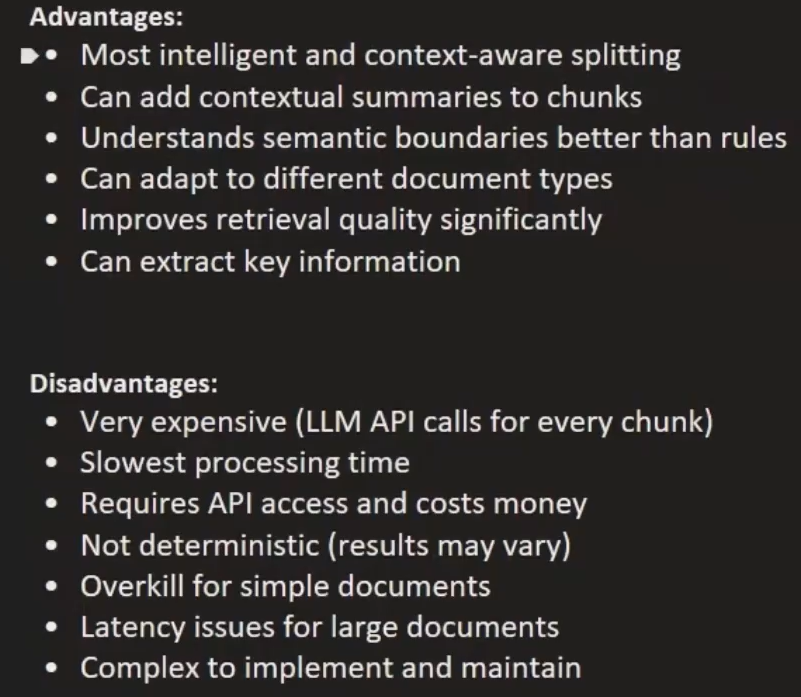